<a href="https://colab.research.google.com/github/kripav2005-glitch/Intermediate-Assessment---2/blob/main/Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

In [3]:
train = pd.read_csv("/content/drive/MyDrive/Data_sciene/Assessment/train_LZdllcl.csv")
test = pd.read_csv("/content/drive/MyDrive/Data_sciene/Assessment/test_2umaH9m.csv")
sample_submission = pd.read_csv("/content/drive/MyDrive/Data_sciene/Assessment/sample_submission_M0L0uXE.csv")

In [4]:
train.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0


In [5]:
test.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
0,8724,Technology,region_26,Bachelor's,m,sourcing,1,24,NaN,1,1,0,77
1,74430,HR,region_4,Bachelor's,f,other,1,31,3.0,5,0,0,51
2,72255,Sales & Marketing,region_13,Bachelor's,m,other,1,31,1.0,4,0,0,47
3,38562,Procurement,region_2,Bachelor's,f,other,3,31,2.0,9,0,0,65
4,64486,Finance,region_29,Bachelor's,m,sourcing,1,30,4.0,7,0,0,61


In [6]:
sample_submission.head()

,employee_id,is_promoted
0,8724,0
1,74430,0
2,72255,0
3,38562,0
4,64486,0


***Exploratory Data Analysis (EDA)***

In [7]:
train.shape

(54808, 14)

In [8]:
test.shape

(23490, 13)

In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  KPIs_met >80%         54808 non-null  int64  
 11  awards_won?           54808 non-null  int64  
 12  avg_training_score    54808 non-null  int64  
 13  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.9+ MB


In [10]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23490 entries, 0 to 23489
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           23490 non-null  int64  
 1   department            23490 non-null  object 
 2   region                23490 non-null  object 
 3   education             22456 non-null  object 
 4   gender                23490 non-null  object 
 5   recruitment_channel   23490 non-null  object 
 6   no_of_trainings       23490 non-null  int64  
 7   age                   23490 non-null  int64  
 8   previous_year_rating  21678 non-null  float64
 9   length_of_service     23490 non-null  int64  
 10  KPIs_met >80%         23490 non-null  int64  
 11  awards_won?           23490 non-null  int64  
 12  avg_training_score    23490 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 2.3+ MB


In [11]:
train.columns

Index(['employee_id', 'department', 'region', 'education', 'gender',
       'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating',
       'length_of_service', 'KPIs_met >80%', 'awards_won?',
       'avg_training_score', 'is_promoted'],
      dtype='object')

In [12]:
test.columns

Index(['employee_id', 'department', 'region', 'education', 'gender',
       'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating',
       'length_of_service', 'KPIs_met >80%', 'awards_won?',
       'avg_training_score'],
      dtype='object')

In [13]:
train.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
count,54808.000000,54808.000000,54808.000000,50684.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000
mean,39195.830627,1.253011,34.803915,3.329256,5.865512,0.351974,0.023172,63.386750,0.085170
std,22586.581449,0.609264,7.660169,1.259993,4.265094,0.477590,0.150450,13.371559,0.279137
min,1.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000,0.000000
25%,19669.750000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000,0.000000
50%,39225.500000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000,0.000000
75%,58730.500000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,76.000000,0.000000
max,78298.000000,10.000000,60.000000,5.000000,37.000000,1.000000,1.000000,99.000000,1.000000


In [14]:
test.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score
count,23490.000000,23490.000000,23490.000000,21678.000000,23490.000000,23490.000000,23490.000000,23490.000000
mean,39041.399149,1.254236,34.782929,3.339146,5.810387,0.358834,0.022776,63.263133
std,22640.809201,0.600910,7.679492,1.263294,4.207917,0.479668,0.149191,13.411750
min,3.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000
25%,19370.250000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000
50%,38963.500000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000
75%,58690.000000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,76.000000
max,78295.000000,9.000000,60.000000,5.000000,34.000000,1.000000,1.000000,99.000000


In [15]:
train.dtypes

,0
employee_id,int64
department,object
region,object
education,object
gender,object
recruitment_channel,object
no_of_trainings,int64
age,int64
previous_year_rating,float64
length_of_service,int64


In [16]:
test.dtypes

,0
employee_id,int64
department,object
region,object
education,object
gender,object
recruitment_channel,object
no_of_trainings,int64
age,int64
previous_year_rating,float64
length_of_service,int64


In [17]:
train.isnull().sum()

,0
employee_id,0
department,0
region,0
education,2409
gender,0
recruitment_channel,0
no_of_trainings,0
age,0
previous_year_rating,4124
length_of_service,0


In [18]:
test.isnull().sum()

,0
employee_id,0
department,0
region,0
education,1034
gender,0
recruitment_channel,0
no_of_trainings,0
age,0
previous_year_rating,1812
length_of_service,0


In [19]:
train.duplicated().sum()

np.int64(0)

In [20]:
test.duplicated().sum()

np.int64(0)

In [21]:
train["is_promoted"].value_counts()

,count
is_promoted,
0,50140
1,4668


In [22]:
train["is_promoted"].value_counts(normalize=True) * 100

,proportion
is_promoted,
0,91.482995
1,8.517005


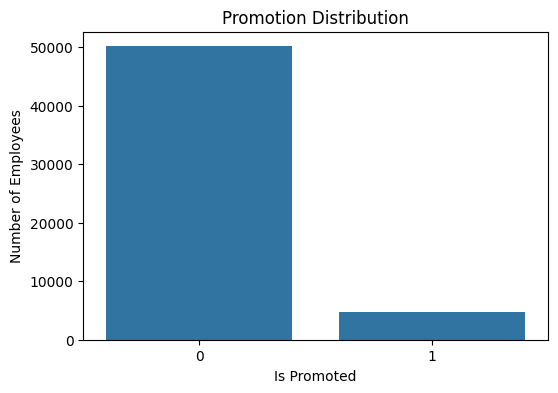

In [23]:
plt.figure(figsize=(6, 4))

sns.countplot(x="is_promoted", data=train)

plt.title("Promotion Distribution")
plt.xlabel("Is Promoted")
plt.ylabel("Number of Employees")

plt.show()

In [24]:
numerical_columns = train.select_dtypes(include=np.number).columns

numerical_columns

Index(['employee_id', 'no_of_trainings', 'age', 'previous_year_rating',
       'length_of_service', 'KPIs_met >80%', 'awards_won?',
       'avg_training_score', 'is_promoted'],
      dtype='object')

In [25]:
categorical_columns = train.select_dtypes(include="object").columns

categorical_columns

Index(['department', 'region', 'education', 'gender', 'recruitment_channel'], dtype='object')

In [26]:
pd.crosstab(
    train["department"],
    train["is_promoted"],
    normalize="index"
) * 100

is_promoted,0,1
department,,
Analytics,90.433483,9.566517
Finance,91.876972,8.123028
HR,94.375517,5.624483
Legal,94.898941,5.101059
Operations,90.985196,9.014804
Procurement,90.361446,9.638554
R&D,93.093093,6.906907
Sales & Marketing,92.796912,7.203088
Technology,89.240684,10.759316


In [27]:
pd.crosstab(
    train["education"],
    train["is_promoted"],
    normalize="index"
) * 100

is_promoted,0,1
education,,
Bachelor's,91.796886,8.203114
Below Secondary,91.677019,8.322981
Master's & above,90.144054,9.855946


In [28]:
pd.crosstab(
    train["gender"],
    train["is_promoted"],
    normalize="index"
) * 100

is_promoted,0,1
gender,,
f,91.006621,8.993379
m,91.684850,8.315150


In [29]:
pd.crosstab(
    train["previous_year_rating"],
    train["is_promoted"],
    normalize="index"
) * 100

is_promoted,0,1
previous_year_rating,,
1.0,98.585891,1.414109
2.0,95.715976,4.284024
3.0,92.722097,7.277903
4.0,92.062367,7.937633
5.0,83.638532,16.361468


In [30]:
pd.crosstab(
    train["awards_won?"],
    train["is_promoted"],
    normalize="index"
) * 100

is_promoted,0,1
awards_won?,,
0,92.325078,7.674922
1,55.984252,44.015748


**Train preprocessing**

In [31]:
train_processed = train.copy()

In [32]:
train_processed = train_processed.drop("employee_id", axis=1)

In [33]:
X_train = train_processed.drop("is_promoted", axis=1)
y_train = train_processed["is_promoted"]

In [34]:
# Categorical columns
categorical_columns = X_train.select_dtypes(include="object").columns

for column in categorical_columns:
    X_train[column] = X_train[column].fillna(X_train[column].mode()[0])

# Numerical columns
numerical_columns = X_train.select_dtypes(include=np.number).columns

for column in numerical_columns:
    X_train[column] = X_train[column].fillna(X_train[column].median())

In [35]:
X_train = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    drop_first=True
)

In [36]:
print("Train shape:", X_train.shape)
print("Missing values:")
print(X_train.isnull().sum().sum())

Train shape: (54808, 53)
Missing values:
0


**Test preprocessing**

In [37]:
test_processed = test.copy()

In [38]:
test_processed = test_processed.drop("employee_id", axis=1)

In [39]:
# Categorical columns
categorical_columns_test = test_processed.select_dtypes(include="object").columns

for column in categorical_columns_test:
    test_processed[column] = test_processed[column].fillna(
        test_processed[column].mode()[0]
    )

# Numerical columns
numerical_columns_test = test_processed.select_dtypes(include=np.number).columns

for column in numerical_columns_test:
    test_processed[column] = test_processed[column].fillna(
        test_processed[column].median()
    )

In [40]:
test_processed = pd.get_dummies(
    test_processed,
    columns=categorical_columns_test,
    drop_first=True
)

In [41]:
print("Test shape:", test_processed.shape)
print("Missing values:")
print(test_processed.isnull().sum().sum())

Test shape: (23490, 53)
Missing values:
0


In [42]:
test_processed = test_processed.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [43]:
print("Train:", X_train.shape)
print("Test :", test_processed.shape)

Train: (54808, 53)
Test : (23490, 53)


**Modeling**

In [44]:
!pip -q install xgboost

In [45]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [46]:
print("Training data:", X_tr.shape)
print("Validation data:", X_val.shape)

print("Training target:", y_tr.shape)
print("Validation target:", y_val.shape)

Training data: (43846, 53)
Validation data: (10962, 53)
Training target: (43846,)
Validation target: (10962,)


In [47]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_tr, y_tr)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

In [48]:
y_pred_logistic = logistic_model.predict(X_val)

accuracy_logistic = accuracy_score(y_val, y_pred_logistic)

print("Logistic Regression Accuracy:", accuracy_logistic)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_logistic))

Logistic Regression Accuracy: 0.931125706987776

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96     10028
           1       0.82      0.24      0.38       934

    accuracy                           0.93     10962
   macro avg       0.88      0.62      0.67     10962
weighted avg       0.92      0.93      0.91     10962



In [49]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_tr, y_tr)

DecisionTreeClassifier(random_state=42)

In [50]:
y_pred_tree = decision_tree.predict(X_val)

accuracy_tree = accuracy_score(y_val, y_pred_tree)

print("Decision Tree Accuracy:", accuracy_tree)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_tree))

Decision Tree Accuracy: 0.8967341725962416

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.94      0.94     10028
           1       0.40      0.45      0.43       934

    accuracy                           0.90     10962
   macro avg       0.68      0.69      0.68     10962
weighted avg       0.90      0.90      0.90     10962



In [51]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_tr, y_tr)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

In [52]:
y_pred_rf = random_forest.predict(X_val)

accuracy_rf = accuracy_score(y_val, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf))

Random Forest Accuracy: 0.9339536580915891

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96     10028
           1       0.82      0.29      0.43       934

    accuracy                           0.93     10962
   macro avg       0.88      0.64      0.70     10962
weighted avg       0.93      0.93      0.92     10962



In [53]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_rf
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.931126
1,Decision Tree,0.896734
2,Random Forest,0.933954


In [54]:
rf_tuned = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_tr, y_tr)

RandomForestClassifier(max_depth=15, min_samples_leaf=2, min_samples_split=5,
                       n_estimators=300, n_jobs=-1, random_state=42)

In [55]:
y_pred_rf_tuned = rf_tuned.predict(X_val)

accuracy_rf_tuned = accuracy_score(y_val, y_pred_rf_tuned)

print("Tuned Random Forest Accuracy:", accuracy_rf_tuned)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf_tuned))

Tuned Random Forest Accuracy: 0.9282977558839628

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96     10028
           1       0.95      0.17      0.28       934

    accuracy                           0.93     10962
   macro avg       0.94      0.58      0.62     10962
weighted avg       0.93      0.93      0.90     10962



In [56]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_rf,
        accuracy_rf_tuned
    ]
})

results.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy
2,Random Forest,0.933954
0,Logistic Regression,0.931126
3,Tuned Random Forest,0.928298
1,Decision Tree,0.896734


In [57]:
from xgboost import XGBClassifier
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1,
    scale_pos_weight=8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [58]:
y_probability = xgb_model.predict_proba(
    X_val
)[:, 1]

print("First 10 probabilities:")
print(y_probability[:10])

First 10 probabilities:
[3.0686557e-01 2.0109909e-03 5.3486973e-04 3.8067199e-02 6.9033937e-03
 7.0166403e-01 4.4200400e-01 1.6398112e-01 3.4057313e-01 2.2968714e-01]


In [59]:
threshold_results = []

for threshold in np.arange(0.05, 0.71, 0.01):

    y_prediction = (
        y_probability >= threshold
    ).astype(int)

    score = f1_score(
        y_val,
        y_prediction
    )

    threshold_results.append(
        [threshold, score]
    )

threshold_results = pd.DataFrame(
    threshold_results,
    columns=["Threshold", "F1_Score"]
)

best_row = threshold_results.loc[
    threshold_results["F1_Score"].idxmax()
]

best_threshold = best_row["Threshold"]
best_f1 = best_row["F1_Score"]

print(
    "Best Threshold:",
    round(best_threshold, 2)
)

print(
    "Best Validation F1:",
    round(best_f1, 4)
)

Best Threshold: 0.7
Best Validation F1: 0.6562


In [60]:
threshold_results.sort_values(
    "F1_Score",
    ascending=False
).head(10)

,Threshold,F1_Score
65,0.70,0.656250
64,0.69,0.646932
62,0.67,0.640320
63,0.68,0.639710
61,0.66,0.639653
60,0.65,0.632319
59,0.64,0.630622
58,0.63,0.627156
57,0.62,0.620128
56,0.61,0.612228


In [61]:
best_validation_prediction = (
    y_probability >= best_threshold
).astype(int)

print(
    classification_report(
        y_val,
        best_validation_prediction
    )
)

              precision    recall  f1-score   support

           0       0.97      0.97      0.97     10028
           1       0.69      0.63      0.66       934

    accuracy                           0.94     10962
   macro avg       0.83      0.80      0.81     10962
weighted avg       0.94      0.94      0.94     10962



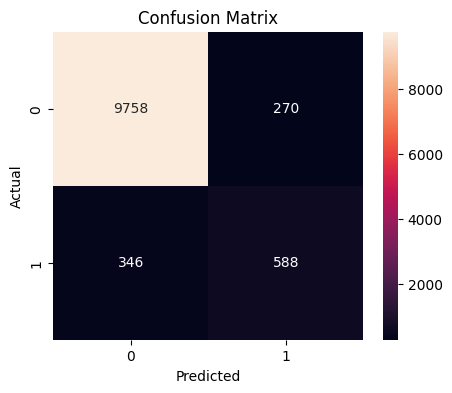

In [62]:
cm = confusion_matrix(
    y_val,
    best_validation_prediction
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [64]:
final_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1,
    scale_pos_weight=8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    X_train,
    y_train
)

print("Final model trained successfully!")

Final model trained successfully!


In [65]:
test_probability = final_model.predict_proba(
    test_processed
)[:, 1]

print("Number of test predictions:", len(test_probability))
print("First 10 probabilities:")
print(test_probability[:10])

Number of test predictions: 23490
First 10 probabilities:
[4.32760417e-01 2.07217736e-03 1.03821534e-04 2.52064108e-03
 7.39080925e-03 7.17665115e-03 3.63478184e-01 1.35354429e-01
 1.36314752e-02 8.17847252e-01]


In [66]:
test_predictions = (
    test_probability >= best_threshold
).astype(int)

print("Prediction counts:")
print(pd.Series(test_predictions).value_counts())

Prediction counts:
0    21809
1     1681
Name: count, dtype: int64


In [67]:
final_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=15, min_samples_leaf=2, min_samples_split=5,
                       n_estimators=300, n_jobs=-1, random_state=42)

In [68]:
test_predictions = final_model.predict(test_processed)

In [69]:
print("Number of predictions:", len(test_predictions))
print("First 10 predictions:", test_predictions[:10])

Number of predictions: 23490
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


In [70]:
submission = sample_submission.copy()

submission["is_promoted"] = test_predictions

print("Submission shape:", submission.shape)

display(submission.head(10))

Submission shape: (23490, 2)


,employee_id,is_promoted
0,8724,0
1,74430,0
2,72255,0
3,38562,0
4,64486,0
5,46232,0
6,54542,0
7,67269,0
8,66174,0
9,76303,0


In [71]:
print("Submission columns:")
print(submission.columns.tolist())

print("\nSubmission shape:")
print(submission.shape)

print("\nMissing values:")
print(submission.isnull().sum())

print("\nPrediction distribution:")
print(submission["is_promoted"].value_counts())

Submission columns:
['employee_id', 'is_promoted']

Submission shape:
(23490, 2)

Missing values:
employee_id    0
is_promoted    0
dtype: int64

Prediction distribution:
is_promoted
0    23157
1      333
Name: count, dtype: int64


In [72]:
submission = sample_submission.copy()

submission.head()

,employee_id,is_promoted
0,8724,0
1,74430,0
2,72255,0
3,38562,0
4,64486,0


In [73]:
submission["is_promoted"] = test_predictions

In [76]:
submission.to_csv(
    "submission.csv",
    index=False
)

In [77]:
check_submission = pd.read_csv("submission.csv")

print(check_submission.shape)
print(check_submission.head())

(23490, 2)
   employee_id  is_promoted
0         8724            0
1        74430            0
2        72255            0
3        38562            0
4        64486            0


In [78]:
submission.to_csv(
    "submission_xgboost.csv",
    index=False
)

print("submission_xgboost.csv created successfully!")

submission_xgboost.csv created successfully!


In [80]:
from google.colab import files

files.download(
    "submission_xgboost.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>